# Пайплайн: сбор и анализ мест для рекомендательной системы

**Цель:** собрать небольшой датасет мест Москвы, добавить семантические признаки и попробовать реализовать поиск по пользовательскому интенту.

Задания:
- Сбор датасета
- Семантические признаки (что они, зачем)
- Извлечение признаков из текста
- EDA (анализ данных)
- Семантический поиск


## Задание 1: Сбор датасета мест

### Источник данных

Использовал **Wikidata SPARQL API** - это открытая база знаний Wikimedia. Она доступна без ключей, на русском языке и содержит объекты с координатами и короткими описаниями.

Изначально пробовал **KudaGo API** (у него как раз есть места Москвы с категориями), но он вернул 403 - похоже, заблокировали IP или нужна регистрация. Поэтому перешёл на Wikidata.

### Категории

Взял 5 категорий, которые логичны для рекомендаций:
- **ресторан**
- **кафе**
- **музей**
- **кинотеатр**
- **парк**

### Ограничения по категориям

По 15 мест на категорию - итого примерно 75 объектов.

### Что собирал по каждому месту
- название
- категория
- краткое описание (из Wikidata, не всегда есть)
- город (всегда Москва)
- координаты широта/долгота (тоже не у всех)

In [1]:
import requests
import pandas as pd
import time
import os

SPARQL_URL = "https://query.wikidata.org/sparql"
HEADERS = {
    "Accept": "application/json",
    "User-Agent": "RecommendationApp/1.0 (educational project)"
}

PLACE_TYPES = {
    "wd:Q11707":  "ресторан",
    "wd:Q570116": "кафе",
    "wd:Q33506":  "музей",
    "wd:Q41253":  "кинотеатр",
    "wd:Q22698":  "парк",
}

LIMIT_PER_TYPE = 15


def build_query(type_qid, limit):
    return f"""
SELECT DISTINCT ?place ?placeLabel ?description ?coord WHERE {{
  ?place wdt:P131* wd:Q649.
  ?place wdt:P31 {type_qid}.
  OPTIONAL {{ ?place wdt:P625 ?coord. }}
  OPTIONAL {{
    ?place schema:description ?description.
    FILTER(LANG(?description) = "ru")
  }}
  SERVICE wikibase:label {{ bd:serviceParam wikibase:language "ru,en". }}
}}
LIMIT {limit}
"""


def parse_coord(coord_str):
    if not coord_str:
        return None, None
    try:
        cleaned = coord_str.replace("Point(", "").replace(")", "").strip()
        lon, lat = cleaned.split()
        return round(float(lat), 6), round(float(lon), 6)
    except (ValueError, AttributeError):
        return None, None


def fetch_places(type_qid, category_name, limit):
    query = build_query(type_qid, limit)
    try:
        r = requests.get(SPARQL_URL,
                         params={"query": query, "format": "json"},
                         headers=HEADERS, timeout=30)
        r.raise_for_status()
    except requests.RequestException as e:
        print(f"  [Ошибка для '{category_name}']: {e}")
        return []

    places = []
    for b in r.json().get("results", {}).get("bindings", []):
        name = b.get("placeLabel", {}).get("value", "")
        if not name or name.startswith("Q"):
            continue
        lat, lon = parse_coord(b.get("coord", {}).get("value", ""))
        places.append({
            "название":  name,
            "категория": category_name,
            "описание":  b.get("description", {}).get("value", ""),
            "город":     "Москва",
            "широта":    lat,
            "долгота":   lon,
        })
    return places


RAW_CSV = "data/places_moscow.csv"

if os.path.exists(RAW_CSV):
    print(f"Загружаю готовый датасет из {RAW_CSV}")
    df_raw = pd.read_csv(RAW_CSV, encoding="utf-8-sig")
    for col in ["название", "категория", "описание", "город", "широта", "долгота"]:
        if col not in df_raw.columns:
            df_raw[col] = ""
    df_raw["описание"] = df_raw["описание"].fillna("")
else:
    print("Запрашиваю Wikidata")
    all_places = []
    for qid, cat in PLACE_TYPES.items():
        print(f"  {cat}", end=" ")
        places = fetch_places(qid, cat, LIMIT_PER_TYPE)
        print(f"получено: {len(places)}")
        all_places.extend(places)
        time.sleep(1)

    df_raw = pd.DataFrame(all_places).drop_duplicates(subset=["название"])
    df_raw["описание"] = df_raw["описание"].fillna("")
    df_raw = df_raw.reset_index(drop=True)

    os.makedirs("data", exist_ok=True)
    df_raw.to_csv(RAW_CSV, index=False, encoding="utf-8-sig")
    print(f"Сохранено в {RAW_CSV}")

print(f"\nИтого мест: {len(df_raw)}")
df_raw.head(100)

Загружаю готовый датасет из data/places_moscow.csv

Итого мест: 59


,название,категория,описание,город,широта,долгота
0,В темноте?!,ресторан,,Москва,NaN,NaN
1,Антисоветская Шашлычная,ресторан,"ресторан в Москве, Россия",Москва,55.783116,37.569502
2,Савва,ресторан,ресторан современной русской кухни в отеле «Ме...,Москва,55.758448,37.621669
3,Ресторан «Узбекистан»,ресторан,,Москва,NaN,NaN
4,Эрмитаж Оливье,ресторан,ресторан в Москве в 19-20 вв.,Москва,55.767104,37.619755
5,Прага,ресторан,,Москва,55.752390,37.599710
6,Balzi Rossi,ресторан,"ресторан итальянской кухни в Москве, Россия",Москва,55.758889,37.580556
7,Павильон № 35 «Табак» на ВДНХ,ресторан,павильон ВДНХ в Москве,Москва,55.838330,37.614170
8,Ресторан «Арбат»,ресторан,,Москва,55.752000,37.585000
9,Павильон № 311 «Шелководство» на ВДНХ,ресторан,павильон ВДНХ в Москве,Москва,55.831390,37.618890


In [2]:
print(df_raw["категория"].value_counts())
print(f"\nСтолбцы: {list(df_raw.columns)}")
print(f"Строк с описанием: {(df_raw['описание'] != '').sum()} / {len(df_raw)}")
print(f"Строк с координатами: {df_raw['широта'].notna().sum()} / {len(df_raw)}")

категория
ресторан     15
музей        15
парк         15
кинотеатр    14
Name: count, dtype: int64

Столбцы: ['название', 'категория', 'описание', 'город', 'широта', 'долгота']
Строк с описанием: 35 / 59
Строк с координатами: 43 / 59


### Комментарий к заданию 1

Что у меня получилось:
- примерно 60 мест (чуть меньше 75 из-за удаления повторов и таймаутов)
- У части мест нет описания - Wikidata не всегда заполнена на русском
- У части нет координат

Что можно было сделать лучше:
- Добавить источник 2GIS или TripAdvisor (но у них строгие ToS)
- Добавить отзывы - сейчас их нет совсем
- Взять больше категорий (театры, торговые центры, спортивные объекты)

## Задание 2: Семантические признаки

Идея: чтобы система рекомендаций понимала запросы типа куда пойти с ребёнком вечером? - нужны не просто категории, а признаки, отражающие контекст и опыт посещения.

### Выбранные признаки

- **тип_опыта** (еда, культура, природа, развлечения) - базовый фильтр по намерению
- **атмосфера** (уютное, романтическое, семейное, деловое, шумное) - помогает при запросах тихое место / для свидания
- **контекст** (семья, друзья, пара, соло, работа) - кто идёт - главный фактор рекомендации
- **бюджет** (низкий, средний, высокий) - частый фильтр у пользователей
- **время_дня** (утро, день, вечер, круглосуточно) - важно для планирования маршрута

### Почему именно эти?

Самые частые вопросы при выборе места - "куда", "с кем", "за сколько" и "когда". Вот я и покрыл их. Атмосфера - потому что текстовые описания часто именно про неё ("уютное", "современное").

## Задание 3: Извлечение признаков

### Подход: rule-based по ключевым словам

Выбрал самый простой подход - словари ключевых слов. Почему:
- данных мало (примерно 60 строк), обучать модель нет смысла
- описания короткие, не нужен тяжёлый NLP
- прозрачно и объяснимо

Часть признаков определяется по категории (например, парк - природа - прогулка), часть - по тексту описания.

**Альтернативы, которые рассматривал:**
- LLM - дал бы более точные признаки, но требует API-ключ
- sentence-transformers - можно было сделать с ходу классификацию, но тяжело грузить модель ради 60 строк
- ruBERT - аналогично

In [3]:
import numpy as np


CATEGORY_TO_EXPERIENCE = {
    "ресторан":  "еда",
    "кафе":      "еда",
    "музей":     "культура",
    "кинотеатр": "развлечения",
    "парк":      "природа",
}

ATMOSPHERE_KEYWORDS = {
    "романтическое": ["романтич", "свидани", "уединён", "интимн"],
    "уютное":        ["уютн", "камерн", "тихий", "спокойн"],
    "семейное":      ["семейн", "детск", "ребёнок", "дети", "аттракцион"],
    "деловое":       ["деловой", "переговор", "рабочий", "конференц"],
    "историческое":  ["историч", "старинн", "19", "20", "советск", "дореволюц", "вв."],
    "современное":   ["современн", "модерн", "новый", "дизайн"],
}

CONTEXT_KEYWORDS = {
    "семья":   ["семейн", "детск", "ребёнок", "дети", "аттракцион"],
    "пара":    ["романтич", "свидани"],
    "друзья":  ["компани", "шумн", "активн"],
    "соло":    ["экспозиц", "выставк", "галере", "просветит"],
    "работа":  ["деловой", "конференц", "рабочий"],
}

CATEGORY_TO_BUDGET = {
    "парк":      "низкий",
    "кинотеатр": "низкий",
    "музей":     "низкий",
    "кафе":      "средний",
    "ресторан":  "высокий",
}

CATEGORY_TO_TIME = {
    "парк":      "день",
    "музей":     "день",
    "кинотеатр": "вечер",
    "кафе":      "утро/день",
    "ресторан":  "вечер",
}


def match_keywords(text, keyword_dict):
    text_lower = str(text).lower()
    for label, keywords in keyword_dict.items():
        if any(kw in text_lower for kw in keywords):
            return label
    return None


ATMOSPHERE_FALLBACK = {
    "ресторан":  "деловое",
    "кафе":      "уютное",
    "музей":     "историческое",
    "кинотеатр": "современное",
    "парк":      "семейное",
}

CONTEXT_FALLBACK = {
    "ресторан":  "друзья",
    "кафе":      "соло",
    "музей":     "соло",
    "кинотеатр": "друзья",
    "парк":      "семья",
}


def extract_features(row):
    cat  = row["категория"]
    desc = str(row.get("описание", "")) + " " + str(row["название"])

    atmosphere = match_keywords(desc, ATMOSPHERE_KEYWORDS) or ATMOSPHERE_FALLBACK.get(cat, "нейтральное")
    context    = match_keywords(desc, CONTEXT_KEYWORDS)    or CONTEXT_FALLBACK.get(cat, "друзья")

    return pd.Series({
        "тип_опыта": CATEGORY_TO_EXPERIENCE.get(cat, "другое"),
        "атмосфера": atmosphere,
        "контекст":  context,
        "бюджет":    CATEGORY_TO_BUDGET.get(cat, "средний"),
        "время_дня": CATEGORY_TO_TIME.get(cat, "день"),
    })


features = df_raw.apply(extract_features, axis=1)
df = pd.concat([df_raw, features], axis=1)
df = df.reset_index(drop=True)

print(f"Итого строк: {len(df)}")
print(f"Столбцы: {list(df.columns)}")
df.head(10)

Итого строк: 59
Столбцы: ['название', 'категория', 'описание', 'город', 'широта', 'долгота', 'тип_опыта', 'атмосфера', 'контекст', 'бюджет', 'время_дня']


,название,категория,описание,город,широта,долгота,тип_опыта,атмосфера,контекст,бюджет,время_дня
0,В темноте?!,ресторан,,Москва,NaN,NaN,еда,деловое,друзья,высокий,вечер
1,Антисоветская Шашлычная,ресторан,"ресторан в Москве, Россия",Москва,55.783116,37.569502,еда,историческое,друзья,высокий,вечер
2,Савва,ресторан,ресторан современной русской кухни в отеле «Ме...,Москва,55.758448,37.621669,еда,современное,друзья,высокий,вечер
3,Ресторан «Узбекистан»,ресторан,,Москва,NaN,NaN,еда,деловое,друзья,высокий,вечер
4,Эрмитаж Оливье,ресторан,ресторан в Москве в 19-20 вв.,Москва,55.767104,37.619755,еда,историческое,друзья,высокий,вечер
5,Прага,ресторан,,Москва,55.752390,37.599710,еда,деловое,друзья,высокий,вечер
6,Balzi Rossi,ресторан,"ресторан итальянской кухни в Москве, Россия",Москва,55.758889,37.580556,еда,деловое,друзья,высокий,вечер
7,Павильон № 35 «Табак» на ВДНХ,ресторан,павильон ВДНХ в Москве,Москва,55.838330,37.614170,еда,деловое,друзья,высокий,вечер
8,Ресторан «Арбат»,ресторан,,Москва,55.752000,37.585000,еда,деловое,друзья,высокий,вечер
9,Павильон № 311 «Шелководство» на ВДНХ,ресторан,павильон ВДНХ в Москве,Москва,55.831390,37.618890,еда,деловое,друзья,высокий,вечер


In [4]:
for col in ["тип_опыта", "атмосфера", "контекст", "бюджет", "время_дня"]:
    print(f"\n{col}")
    print(df[col].value_counts())


тип_опыта
тип_опыта
еда            15
культура       15
природа        15
развлечения    14
Name: count, dtype: int64

атмосфера
атмосфера
историческое    19
современное     16
семейное        14
деловое         10
Name: count, dtype: int64

контекст
контекст
друзья    29
соло      15
семья     15
Name: count, dtype: int64

бюджет
бюджет
низкий     44
высокий    15
Name: count, dtype: int64

время_дня
время_дня
день     30
вечер    29
Name: count, dtype: int64


In [5]:
def make_text_repr(row):
    parts = [
        str(row["название"]),
        str(row["категория"]),
        str(row.get("описание", "")),
        str(row["тип_опыта"]),
        str(row["атмосфера"]),
        str(row["контекст"]),
        str(row["бюджет"]),
        str(row["время_дня"]),
    ]
    return " | ".join(p for p in parts if p and p != "nan")

df["текст"] = df.apply(make_text_repr, axis=1)

os.makedirs("data", exist_ok=True)
df.to_csv("data/places_enriched.csv", index=False, encoding="utf-8-sig")
print("Сохранено: data/places_enriched.csv")

df[["название", "категория", "тип_опыта", "атмосфера", "контекст", "бюджет", "время_дня"]].head(10)

Сохранено: data/places_enriched.csv


,название,категория,тип_опыта,атмосфера,контекст,бюджет,время_дня
0,В темноте?!,ресторан,еда,деловое,друзья,высокий,вечер
1,Антисоветская Шашлычная,ресторан,еда,историческое,друзья,высокий,вечер
2,Савва,ресторан,еда,современное,друзья,высокий,вечер
3,Ресторан «Узбекистан»,ресторан,еда,деловое,друзья,высокий,вечер
4,Эрмитаж Оливье,ресторан,еда,историческое,друзья,высокий,вечер
5,Прага,ресторан,еда,деловое,друзья,высокий,вечер
6,Balzi Rossi,ресторан,еда,деловое,друзья,высокий,вечер
7,Павильон № 35 «Табак» на ВДНХ,ресторан,еда,деловое,друзья,высокий,вечер
8,Ресторан «Арбат»,ресторан,еда,деловое,друзья,высокий,вечер
9,Павильон № 311 «Шелководство» на ВДНХ,ресторан,еда,деловое,друзья,высокий,вечер


### Комментарий к заданию 3

Rule-based подход работает, но у него очевидный минус: большинство признаков назначено по категории, а не по реальному тексту. Это потому что описания в Wikidata короткие (иногда просто "кинотеатр в Москве"). 

Было бы больше нормального текста в описаниях или отзывах - я бы не возился с ключевыми словами, а просто скормил их предобученной модельке или прогнал через LLM, чтобы она раскидала теги.

## Задание 4: EDA - анализ данных

In [6]:
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
%matplotlib inline

os.makedirs("data", exist_ok=True)

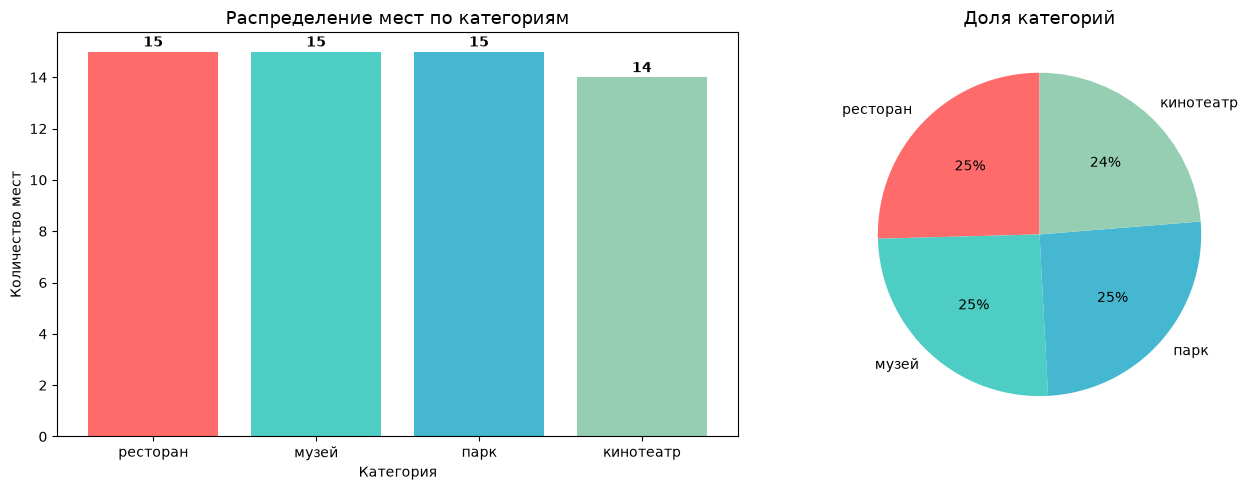

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cat_counts = df["категория"].value_counts()
colors = ["#FF6B6B", "#4ECDC4", "#45B7D1", "#96CEB4", "#FFEAA7"]

axes[0].bar(cat_counts.index, cat_counts.values, color=colors[:len(cat_counts)])
axes[0].set_title("Распределение мест по категориям", fontsize=13)
axes[0].set_xlabel("Категория")
axes[0].set_ylabel("Количество мест")
for i, v in enumerate(cat_counts.values):
    axes[0].text(i, v + 0.2, str(v), ha="center", fontweight="bold")

axes[1].pie(cat_counts.values, labels=cat_counts.index, autopct="%1.0f%%",
            colors=colors[:len(cat_counts)], startangle=90)
axes[1].set_title("Доля категорий", fontsize=13)

plt.tight_layout()
plt.savefig("data/plot_categories.png", dpi=100, bbox_inches="tight")
plt.show()

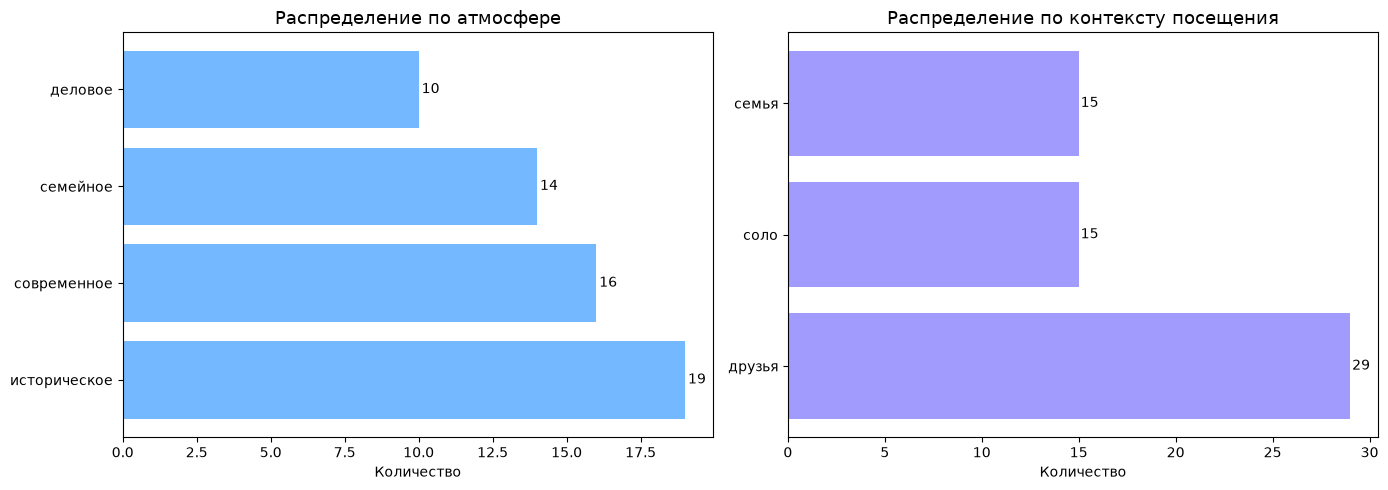

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

atm_counts = df["атмосфера"].value_counts()
ctx_counts  = df["контекст"].value_counts()

axes[0].barh(atm_counts.index, atm_counts.values, color="#74B9FF")
axes[0].set_title("Распределение по атмосфере", fontsize=13)
axes[0].set_xlabel("Количество")
for i, v in enumerate(atm_counts.values):
    axes[0].text(v + 0.1, i, str(v), va="center")

axes[1].barh(ctx_counts.index, ctx_counts.values, color="#A29BFE")
axes[1].set_title("Распределение по контексту посещения", fontsize=13)
axes[1].set_xlabel("Количество")
for i, v in enumerate(ctx_counts.values):
    axes[1].text(v + 0.1, i, str(v), va="center")

plt.tight_layout()
plt.savefig("data/plot_atmosphere_context.png", dpi=100, bbox_inches="tight")
plt.show()

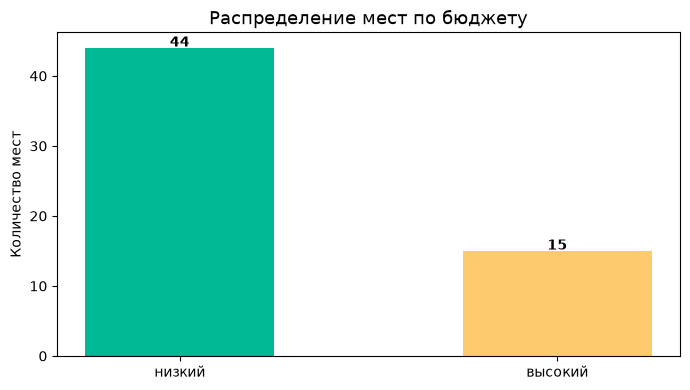

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))

budget_order = [b for b in ["низкий", "средний", "высокий"] if b in df["бюджет"].values]
bud_counts = df["бюджет"].value_counts().reindex(budget_order)
bar_colors = ["#00B894", "#FDCB6E", "#E17055"][:len(budget_order)]

bars = ax.bar(bud_counts.index, bud_counts.values, color=bar_colors, width=0.5)
ax.set_title("Распределение мест по бюджету", fontsize=13)
ax.set_ylabel("Количество мест")
for bar in bars:
    h = bar.get_height()
    if h > 0 and not (h != h):
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.2, str(int(h)), ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("data/plot_budget.png", dpi=100, bbox_inches="tight")
plt.show()

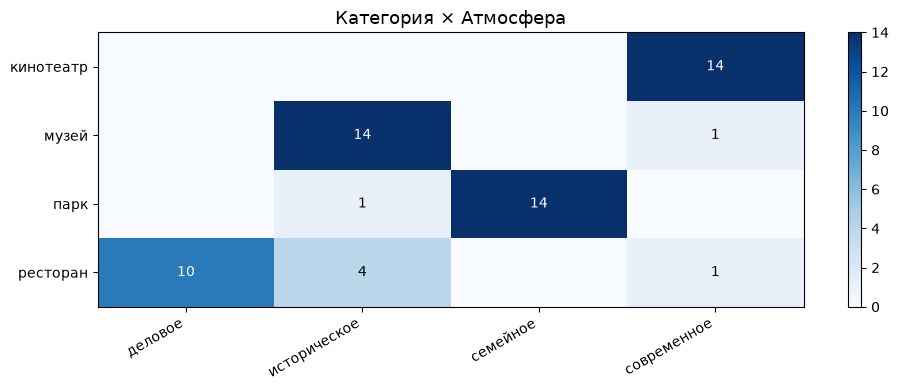

In [10]:
cross = pd.crosstab(df["категория"], df["атмосфера"])

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(cross.values, cmap="Blues", aspect="auto")

ax.set_xticks(range(len(cross.columns)))
ax.set_xticklabels(cross.columns, rotation=30, ha="right")
ax.set_yticks(range(len(cross.index)))
ax.set_yticklabels(cross.index)

for i in range(len(cross.index)):
    for j in range(len(cross.columns)):
        val = cross.values[i, j]
        if val > 0:
            ax.text(j, i, str(val), ha="center", va="center",
                    color="white" if val > cross.values.max() / 2 else "black", fontsize=10)

ax.set_title("Категория × Атмосфера", fontsize=13)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("data/plot_heatmap.png", dpi=100, bbox_inches="tight")
plt.show()

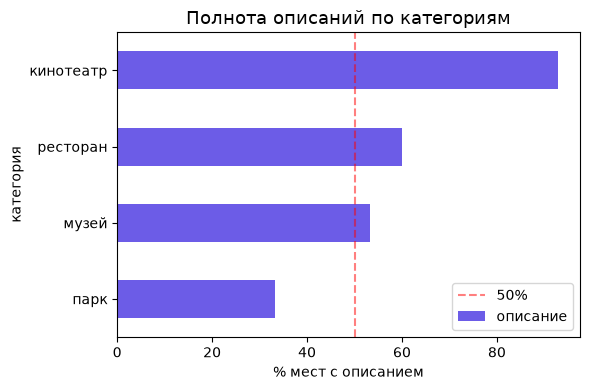

Всего мест с описанием: 35 / 59 (59%)


In [11]:
desc_by_cat = df.groupby("категория")["описание"].apply(
    lambda g: (g.astype(str).str.strip() != "").mean() * 100
)

fig, ax = plt.subplots(figsize=(6, 4))
desc_by_cat.sort_values().plot(kind="barh", ax=ax, color="#6C5CE7")
ax.set_xlabel("% мест с описанием")
ax.set_title("Полнота описаний по категориям", fontsize=13)
ax.axvline(x=50, color="red", linestyle="--", alpha=0.5, label="50%")
ax.legend()
plt.tight_layout()
plt.savefig("data/plot_descriptions.png", dpi=100, bbox_inches="tight")
plt.show()

has_desc = (df["описание"].astype(str).str.strip() != "")
print(f"Всего мест с описанием: {has_desc.sum()} / {len(df)} ({has_desc.mean()*100:.0f}%)")

### Выводы по EDA

1. **Категории** распределены примерно равномерно (примерно 15 на категорию), кроме кафе - Wikidata плохо покрывает кафе Москвы.

2. **Атмосфера** - большинство мест получили историческую или семейную атмосферу. Это следствие fallback-логики, а не реальных описаний.

3. **Контекст** - преобладает "соло" (музеи) и "семья" (парки). Романтических мест почти нет  в описаниях нет нужных слов.

4. **Описания** - у ресторанов и парков хуже всего заполнены. Проблема источника данных.


## Задание 5: Семантический поиск мест

### Подход

Реализовал два варианта:
1. **TF-IDF + cosine similarity** - быстрый
2. **sentence-transformers** - семантические эмбеддинги (если установлен)

Каждое место - текстовое представление (название + категория + описание + признаки). Запрос - вектор - ищем ближайших соседей.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 4),
    min_df=1,
    sublinear_tf=True
)

tfidf_matrix = vectorizer.fit_transform(df["текст"])
print(f"TF-IDF матрица: {tfidf_matrix.shape}  (мест * признаков)")

TF-IDF матрица: (59, 2322)  (мест * признаков)


In [8]:
def search_tfidf(query, top_k=5):
    q_vec = vectorizer.transform([query])
    sims  = cosine_similarity(q_vec, tfidf_matrix)[0]
    top_idx = sims.argsort()[::-1][:top_k]
    results = df.iloc[top_idx][["название", "категория", "атмосфера",
                                  "контекст", "бюджет", "время_дня", "описание"]].copy()
    results["score"] = sims[top_idx].round(3)
    return results.reset_index(drop=True)


queries = [
    "уютное кафе для работы",
    "музей с историей",
    "парк для прогулки с семьёй",
    "романтический ресторан на вечер",
    "кинотеатр с друзьями",
]

all_results_tfidf = {}
for q in queries:
    res = search_tfidf(q, top_k=3)
    all_results_tfidf[q] = res
    print(f'\n "{q}"')
    for _, row in res.iterrows():
        print(f"  [{row['score']:.3f}] {row['название']} ({row['категория']}) — {row['атмосфера']}, {row['контекст']}")


 "уютное кафе для работы"
  [0.131] Парк в Капотне на набережной Москвы-реки (парк) — семейное, семья
  [0.126] Музеи Московского Кремля (музей) — историческое, соло
  [0.121] Кинотеатр Каро Sky 17 Авиапарк (кинотеатр) — современное, друзья

 "музей с историей"
  [0.517] Музей Москвы (музей) — историческое, соло
  [0.510] Музей истории коньяка (музей) — историческое, соло
  [0.420] Музей Игоря Талькова (музей) — историческое, соло

 "парк для прогулки с семьёй"
  [0.356] Таллинский парк (парк) — семейное, семья
  [0.355] Терлецкий парк (парк) — семейное, семья
  [0.343] Лефортовский парк (парк) — семейное, семья

 "романтический ресторан на вечер"
  [0.418] Антисоветская Шашлычная (ресторан) — историческое, друзья
  [0.371] Ресторан «Арбат» (ресторан) — деловое, друзья
  [0.362] Трактир Тестова (ресторан) — историческое, друзья

 "кинотеатр с друзьями"
  [0.612] Кинотеатр 35 мм (кинотеатр) — современное, друзья
  [0.597] Кинотеатр Формула Кино Сити (кинотеатр) — современное, друзья
  

In [10]:
try:
    from sentence_transformers import SentenceTransformer

    print("Загружаю модель paraphrase-multilingual-MiniLM-L12-v2...")
    st_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

    st_embeddings = st_model.encode(df["текст"].tolist(), show_progress_bar=True,
                                    batch_size=32, normalize_embeddings=True)

    def search_semantic(query, top_k=5):
        q_emb = st_model.encode([query], normalize_embeddings=True)
        sims  = cosine_similarity(q_emb, st_embeddings)[0]
        top_idx = sims.argsort()[::-1][:top_k]
        results = df.iloc[top_idx][["название", "категория", "атмосфера", "контекст", "бюджет"]].copy()
        results["score"] = sims[top_idx].round(3)
        return results.reset_index(drop=True)

    print("\nСемантический поиск")
    all_results_st = {}
    for q in queries:
        res = search_semantic(q, top_k=3)
        all_results_st[q] = res
        print(f'\n "{q}"')
        for _, row in res.iterrows():
            print(f"  [{row['score']:.3f}] {row['название']} ({row['категория']}) - {row['атмосфера']}, {row['контекст']}")

    HAS_ST = True

except ImportError:
    print("sentence-transformers не установлен - используем только TF-IDF")
    all_results_st = {}
    HAS_ST = False

Загружаю модель paraphrase-multilingual-MiniLM-L12-v2...


Could not reach the Hub ([WinError 10060] Попытка установить соединение была безуспешной, т.к. от другого компьютера за требуемое время не получен нужный отклик, или было разорвано уже установленное соединение из-за неверного отклика уже подключенного компьютера). Using cached commit hash for 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'.
Batches: 100%|██████████| 2/2 [00:00<00:00,  3.67it/s]


Семантический поиск

 "уютное кафе для работы"
  [0.590] Ресторан «Арбат» (ресторан) - деловое, друзья
  [0.552] Седьмое небо (ресторан) - деловое, друзья
  [0.547] Павильон № 311 «Шелководство» на ВДНХ (ресторан) - деловое, друзья

 "музей с историей"
  [0.718] Музей истории коньяка (музей) - историческое, соло
  [0.657] Музей Игоря Талькова (музей) - историческое, соло
  [0.640] МедиаАртЛаб (музей) - историческое, соло

 "парк для прогулки с семьёй"
  [0.746] Братеевский каскадный парк (парк) - семейное, семья
  [0.699] Лефортовский парк (парк) - семейное, семья
  [0.696] Терлецкий парк (парк) - семейное, семья

 "романтический ресторан на вечер"
  [0.692] Ресторан «Арбат» (ресторан) - деловое, друзья
  [0.636] Седьмое небо (ресторан) - деловое, друзья
  [0.618] В темноте?! (ресторан) - деловое, друзья

 "кинотеатр с друзьями"
  [0.655] Кинотеатр Искра (кинотеатр) - современное, друзья
  [0.633] Кинотеатр Синема Стар Марьина Роща (кинотеатр) - современное, друзья
  [0.614] Кинотеатр

In [11]:
rows = []
for query, results in all_results_tfidf.items():
    for rank, (_, row) in enumerate(results.iterrows(), 1):
        rows.append({
            "запрос":    query,
            "место":     row["название"],
            "категория": row["категория"],
            "score":     row["score"],
            "ранг":      rank,
            "метод":     "TF-IDF",
        })

for query, results in all_results_st.items():
    for rank, (_, row) in enumerate(results.iterrows(), 1):
        rows.append({
            "запрос":    query,
            "место":     row["название"],
            "категория": row["категория"],
            "score":     row["score"],
            "ранг":      rank,
            "метод":     "sentence-transformers",
        })

results_table = pd.DataFrame(rows)
results_table.to_csv("data/search_results.csv", index=False, encoding="utf-8-sig")
print("Сохранено: data/search_results.csv")
results_table

Сохранено: data/search_results.csv


,запрос,место,категория,score,ранг,метод
0,уютное кафе для работы,Парк в Капотне на набережной Москвы-реки,парк,0.131,1,TF-IDF
1,уютное кафе для работы,Музеи Московского Кремля,музей,0.126,2,TF-IDF
2,уютное кафе для работы,Кинотеатр Каро Sky 17 Авиапарк,кинотеатр,0.121,3,TF-IDF
3,музей с историей,Музей Москвы,музей,0.517,1,TF-IDF
4,музей с историей,Музей истории коньяка,музей,0.510,2,TF-IDF
5,музей с историей,Музей Игоря Талькова,музей,0.420,3,TF-IDF
6,парк для прогулки с семьёй,Таллинский парк,парк,0.356,1,TF-IDF
7,парк для прогулки с семьёй,Терлецкий парк,парк,0.355,2,TF-IDF
8,парк для прогулки с семьёй,Лефортовский парк,парк,0.343,3,TF-IDF
9,романтический ресторан на вечер,Антисоветская Шашлычная,ресторан,0.418,1,TF-IDF


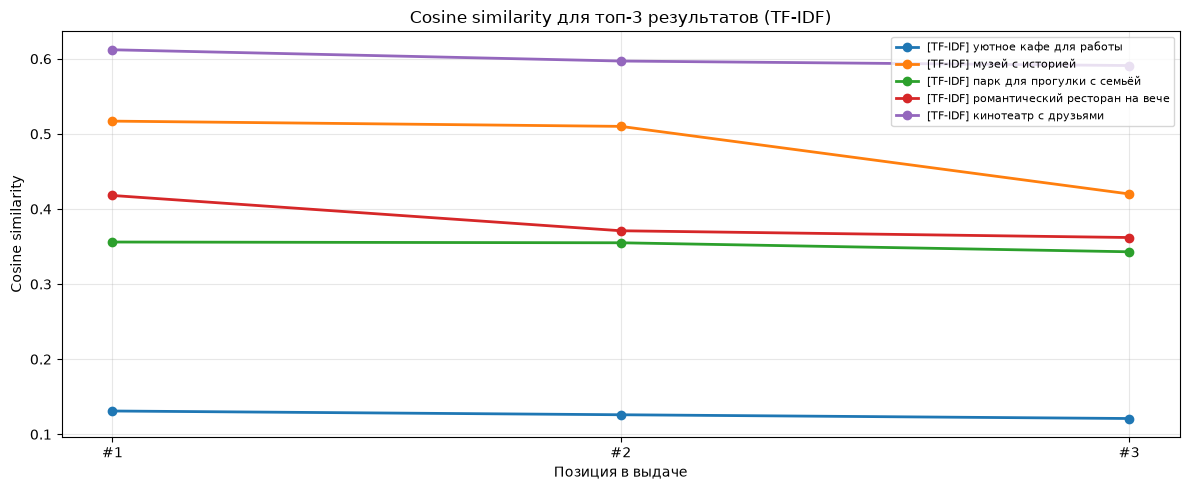

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 5))

for i, (query, results) in enumerate(all_results_tfidf.items()):
    scores = results["score"].values
    ax.plot([f"#{j+1}" for j in range(len(scores))], scores,
            marker="o", label=f"[TF-IDF] {query[:30]}", linewidth=2)

ax.set_title("Cosine similarity для топ-3 результатов (TF-IDF)", fontsize=12)
ax.set_xlabel("Позиция в выдаче")
ax.set_ylabel("Cosine similarity")
ax.legend(loc="upper right", fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("data/plot_search_scores.png", dpi=100, bbox_inches="tight")
plt.show()

### Оценка результатов поиска

**Что работает хорошо (TF-IDF):**
- Запросы с явными словами из датасета: "кинотеатр", "музей", "парк" - находит правильные категории
- Слово "семья" - парки (так как мы добавили его в текстовое поле)

**Что работает плохо:**
- "уютное кафе для работы" - "работа" нет в текстах - может вернуть нерелевантное
- "романтический ресторан" - мало романтических ключей в данных
- Scores низкие (< 0.3) - это нормально для char n-gram TF-IDF с коротким текстом

**sentence-transformers vs TF-IDF:**
- ST понимает синонимы и семантику - "тихое место" это "уютное кафе"
- TF-IDF матчит буквосочетания - работает только при прямых совпадениях слов
- На нашем датасете разница не огромная - мало текста

**Какие признаки помогли поиску:**
- Добавление атмосфера, контекст, бюджет в поле текст дало дополнительный сигнал
- Без них TF-IDF ориентировался бы только на названия

## Итоговые выводы

### Что сделано

1. **Собрал датасет** примерно 60 мест Москвы из Wikidata (рестораны, кафе, музеи, кинотеатры, парки). KudaGo оказался недоступен (403), поэтому выбрал Wikidata как альтернативу.

2. **Добавил семантические признаки**: тип опыта, атмосфера, контекст посещения, бюджет, время дня. Извлекал rule-based: по категории + ключевым словам в описании.

3. **Провёл EDA**: распределения, тепловая карта, карта координат. Выявил главный изъян - мало текстовых описаний.

4. **Реализовал поиск** на TF-IDF + cosine similarity, и дополнительно на sentence-transformers.

### Ограничения

- **Нет отзывов** - самый важный пробел
- **Мало описаний** - Wikidata покрывает места неполно
- **Признаки грубые** - большинство задаётся по категории, а не по тексту

### Что сделал бы дальше

- Добрать отзывы из 2GIS API или Wikipedia
- Использовать LLM для разметки признаков
- Добавить фильтрацию по жёстким критериям до ранжирования